# TP1 — Optimisation continue et linéaire

**Séance 1 — Optimisation pour l'IA — MS IA de Confiance, CentraleSupélec**

Dans ce TP vous allez, **étape par étape** :

1. Implémenter la **descente de gradient** à partir de zéro et étudier l'effet du pas.
2. Implémenter et comparer une méthode **accélérée (momentum / Nesterov)**.
3. Résoudre un **problème continu contraint** avec une méthode de barrière, `scipy.optimize`, et `cvxpy`.
4. Formuler et résoudre un **programme linéaire** avec `scipy.optimize.linprog` et `PuLP`, et le comparer à votre résolution du simplexe à la main faite en TD.
5. Démarrer votre **projet individuel ExedBike (Partie 1)**.

**Comment ce notebook est organisé.** Chaque exercice est découpé en petites étapes : une cellule **`# A COMPLETER`** à écrire, suivie presque toujours d'une cellule **de vérification** (marquée ✅) qui teste automatiquement votre code et vous dit si c'est correct — lancez les cellules **dans l'ordre**, une par une, et ne passez à la suivante que lorsque la vérification est au vert. Aucune solution n'est donnée à l'avance : le but est que chaque ligne que vous exécutez, vous l'ayez écrite (ou complétée) vous-même.

Bibliothèques nécessaires : `numpy`, `matplotlib`, `autograd`, `scipy`, `cvxpy`, `pulp`.

> **Installation / choix du kernel.** La cellule suivante installe automatiquement les paquets manquants dans le kernel Python actuellement sélectionné. Si vous obtenez malgré tout `ModuleNotFoundError` : vérifiez le **kernel** utilisé par ce notebook (dans VS Code : en haut à droite du notebook, bouton "Select Kernel" ; dans Jupyter : menu Kernel > Change kernel). Un `ModuleNotFoundError` sur `numpy` en particulier signifie presque toujours que le kernel sélectionné pointe vers un interpréteur Python différent de celui où les paquets sont installés (ou vers un interpréteur « nu » sans aucun paquet) — sélectionnez un autre kernel, ou relancez la cellule ci-dessous puis **redémarrez le kernel** (Restart) avant de continuer.

## Initialisation de l'environnement Python/notebook

In [19]:
import sys, subprocess, importlib
import numpy as np
import matplotlib.pyplot as plt
from autograd import grad
import autograd.numpy as anp

In [3]:
def _ensure(pkg, import_name=None):
    import_name = import_name or pkg
    try:
        importlib.import_module(import_name)
    except ImportError:
        # G. Raty 2029-09-24 : je suis sous uv, donc je modifie légèrement les lignes ci dessous
        # print(f"[setup] installation de {pkg} dans {sys.executable} ...")
        # subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        print(f"[setup] installation de {pkg} avec uv dans le projet...")
        subprocess.run(["uv", "pip", "install", "-q", pkg], check=False)


for _pkg, _imp in [
    ("numpy", "numpy"), ("scipy", "scipy"), ("matplotlib", "matplotlib"),
    ("autograd", "autograd"), ("cvxpy", "cvxpy"), ("pulp", "pulp"),
]:
    _ensure(_pkg, _imp)

import numpy as np
import matplotlib.pyplot as plt
from autograd import grad
import autograd.numpy as anp

np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 4)
print("[setup] environnement pret :", sys.executable)


[setup] environnement pret : c:\Data\Python\Optimisation IA\S1-LP\.venv\Scripts\python.exe


## Exercice 1 — Descente de gradient à partir de zéro

Rappel de la règle de mise à jour :
$$ \mathbf{w}_{k+1} = \mathbf{w}_k - \alpha \nabla J(\mathbf{w}_k). $$

**1.1** Complétez `gradient_descent` ci-dessous : à chaque itération, calculez le gradient de `cost_fun` au point courant (utilisez `g`, déjà construit avec `autograd`), arrêtez-vous si sa norme passe sous `eps`, sinon mettez à jour `w` et ajoutez le nouveau point à `history`.

In [4]:
def gradient_descent(cost_fun, w_init, alpha, epochs, eps=1e-12):
    '''Minimise cost_fun par descente de gradient.

    ENTREES
    cost_fun : callable, fonction de coût J(w)
    w_init   : array-like, point initial
    alpha    : float, pas (learning rate)
    epochs   : int, nombre maximal d'itérations
    eps      : float, arrêt si la norme du gradient passe sous eps

    SORTIES
    w       : point final (np.array)
    history : liste des itérés successifs (y compris w_init)
    '''
    w = np.array(w_init, dtype=float)
    history = [w.copy()]
    # g(w) renvoie le gradient de cost_fun en w (autograd)
    g = grad(cost_fun)   # type: ignore 

    for k in range(epochs):
        # A COMPLETER (3-4 lignes) :
        # 1) calculez gk = g(w) (convertissez en np.array)
        g_k =  np.array(g(w))

        # 2) si la norme de gk est < eps : "break"
        norm = np.linalg.norm(g_k)
        if norm < eps : break

        # 3) sinon : mettez à jour w = w - alpha * gk
        w = w - alpha*g_k

        # 4) ajoutez une copie de w à "history"
        history.append(w.copy())
        # raise NotImplementedError("Complétez gradient_descent")

    return w, history


**✅ Vérification 1.1** — testez `gradient_descent` sur un problème 1D trivial dont vous connaissez la solution exacte : $J(w) = (w-3)^2$, minimum en $w=3$.

In [5]:
def _J1d(w):
    return (w[0] - 3.0) ** 2

_w_check, _hist_check = gradient_descent(_J1d, w_init=[0.0], alpha=0.1, epochs=500, eps=1e-12)

assert abs(_w_check[0] - 3.0) < 1e-3, f"attendu w*≈3.0, obtenu {_w_check[0]}"
assert len(_hist_check) > 1, "history doit contenir plusieurs points"

print(f"OK : convergé en {len(_hist_check)-1} itérations vers w* = {_w_check[0]:.5f}")

# pour voir les variable
w_check, hist_check = _w_check, _hist_check

OK : convergé en 132 itérations vers w* = 3.00000


**1.2** Appliquez la descente de gradient au bol quadratique
$$ J(w_1, w_2) = 3(w_1 - 1)^2 + (w_2 + 2)^2 $$
en partant de $w_0 = (4, 3)$, pour $\alpha = 0.05$ **puis** $\alpha = 0.3$.  
La fonction `show_history` ci-dessous (déjà écrite) trace les lignes de niveau de $J$ et la trajectoire des itérés — complétez juste la boucle qui appelle `gradient_descent` pour chaque `alpha` et affiche le résultat.

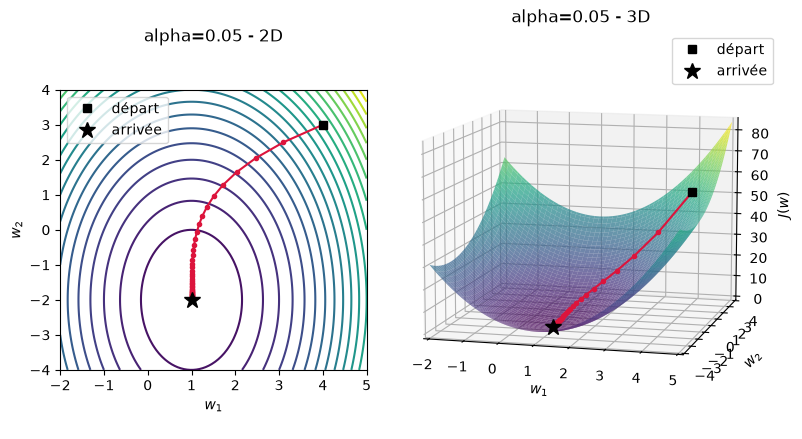

Nombre d'itération :61 | w=1.00000


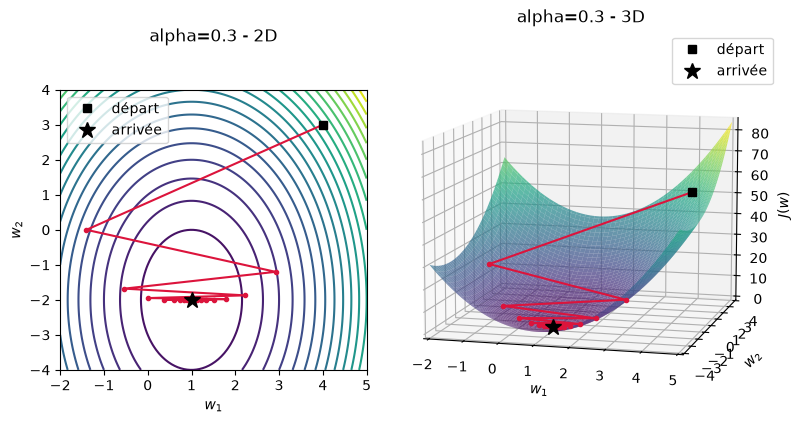

Nombre d'itération :61 | w=1.00000


In [6]:
import matplotlib.gridspec as gridspec

def J_quad(w):
    return 3 * (w[0] - 1) ** 2 + (w[1] + 2) ** 2

def show_history(history, cost_fun, xlim, ylim, title=""):
    a_values, b_values = np.meshgrid(np.linspace(*xlim), np.linspace(*ylim))
    Z = np.array([cost_fun([a, b]) for a, b in zip(a_values.flat, b_values.flat)]).reshape(a_values.shape)

    plt.figure()
    plt.contour(a_values, b_values, Z, levels=20, cmap="viridis")
    
    h = np.array(history)
    plt.plot(h[:, 0], h[:, 1], "o-", color="crimson", markersize=3)
    plt.plot(h[0, 0], h[0, 1], "ks", label="départ")
    plt.plot(h[-1, 0], h[-1, 1], "k*", markersize=12, label="arrivée")
    plt.legend()
    plt.title(title)
    plt.xlabel("$w_1$")
    plt.ylabel("$w_2$")
    plt.show()

# avec de la 3D "pour le sport" (pas que...)
def show_history_3d(history, cost_fun, xlim, ylim, title=""):
    a_values, b_values = np.meshgrid(np.linspace(*xlim), np.linspace(*ylim))
    Z = np.array([cost_fun([a, b]) for a, b in zip(a_values.flat, b_values.flat)]).reshape(a_values.shape)
    
    # Trajectoire de la descente de gradient
    h  = np.array(history)
    # on recalcule l'axe z juste pour les points de l'histo
    h_z = np.array([cost_fun([w1, w2]) for w1, w2 in zip(h[:, 0], h[:, 1])])

    fig = plt.figure(figsize=(8,5))
    # colonnes de même taille
    gs = gridspec.GridSpec(1, 2, width_ratios=[1,1.3])

    # partie 2D
    ax_2d = fig.add_subplot(gs[0])
    ax_2d.contour(a_values, b_values, Z, levels=20, cmap="viridis")
    ax_2d.plot(h[:, 0], h[:, 1], "o-", color="crimson", markersize=3)
    ax_2d.plot(h[0, 0], h[0, 1], "ks", label="départ")
    ax_2d.plot(h[-1, 0], h[-1, 1], "k*", markersize=12, label="arrivée")
    ax_2d.legend()
    ax_2d.set_title(f"{title} - 2D\n\n")
    ax_2d.set_xlabel("$w_1$")
    ax_2d.set_ylabel("$w_2$")
    ax_2d.set_aspect(0.8)
    ax_2d.margins(50)

    # # partie 3D
    ax_3d = fig.add_subplot(gs[1], projection='3d')
    ax_3d.plot_surface(a_values, b_values, Z, cmap="viridis", alpha=0.7, edgecolor='none')
    ax_3d.plot(h[:, 0], h[:, 1], h_z, "o-", color="crimson", markersize=3, zorder=10)
    ax_3d.plot([h[0, 0]], [h[0, 1]], [h_z[0]], 'ks', label="départ",zorder=10) 
    ax_3d.plot([h[-1, 0]], [h[-1, 1]], [h_z[-1]], 'k*', markersize=12, label="arrivée",zorder=10)

    ax_3d.view_init(elev=10, azim=-75)
    ax_3d.set_title(f"{title} - 3D")
    ax_3d.set_xlabel("$w_1$")
    ax_3d.set_ylabel("$w_2$")
    ax_3d.set_zlabel("$J(w)$")
    ax_3d.legend()
    ax_3d.margins(0)
    
    plt.tight_layout()
    
    plt.show()

 
# A COMPLETER : pour alpha dans [0.05, 0.3], appelez gradient_descent(J_quad, w_init=[4.0, 3.0],
# alpha=alpha, epochs=60), puis show_history(hist, J_quad, xlim=(-1, 5), ylim=(-4, 4), title=...)
for alpha in [0.05, 0.3] : 
    # init w
    w0 = [4.0, 3.0]

    w , history = gradient_descent(
        cost_fun=J_quad,
        w_init=w0, 
        alpha=alpha, 
        epochs=60
        )

    show_history_3d(
        history,
        J_quad,
        xlim=(-2, 5, 100),
        ylim=(-4, 4, 100),
        title=f"alpha={alpha}"
    )

    print(f"Nombre d'itération :{len(history)} | w={w[0]:.5f}")


    # raise NotImplementedError("Complétez la boucle ci-dessus")


**Vos observations :** *(à rédiger ici avant de continuer)*  
*Pourquoi la trajectoire zigzague-t-elle pour l'un des deux `alpha` et pas pour l'autre ?  
Indice : regardez le conditionnement de la Hessienne de $J$ (le rapport entre ses deux coefficients quadratiques, $3$ et $1$).*

>La matrice Hessienne (matrice des dérivées 2nde = "vitesse" de la courbure du gradient) donne :
>
>$$H = \begin{pmatrix} 6 & 0 \\ 0 & 2 \end{pmatrix}$$
>les coefficients quadratiques ont un rapport de 3 sur 1 : Le gradient descent 3x plus vitre sur les $w_1$ que les $w_2$  
>Avec un learning rate $\alpha=0.3$ les sauts sont plus élevés et la fonction "rebondie" tout en ateignant le même minimum

## Exercice 2 — Méthodes accélérées : momentum & Nesterov

**2.1** Implémentez le **momentum (heavy-ball)** :
$$ \mathbf{v}_{k+1} = \beta \mathbf{v}_k - \alpha \nabla J(\mathbf{w}_k), \qquad \mathbf{w}_{k+1} = \mathbf{w}_k + \mathbf{v}_{k+1} $$
et le **gradient accéléré de Nesterov** :
$$ \mathbf{v}_{k+1} = \beta \mathbf{v}_k - \alpha \nabla J(\mathbf{w}_k + \beta \mathbf{v}_k), \qquad \mathbf{w}_{k+1} = \mathbf{w}_k + \mathbf{v}_{k+1} $$
Les deux se codent dans **une seule** fonction `momentum_gd` : le paramètre `nesterov` choisit si le gradient est évalué en `w` (momentum) ou au point "anticipé" `w + beta*v` (Nesterov).

In [7]:
def momentum_gd(cost_fun, w_init, alpha, beta, epochs, eps=1e-12, nesterov=False):
    w = np.array(w_init, dtype=float)
    v = np.zeros_like(w)
    history = [w.copy()]
    g = grad(cost_fun)  # type: ignore

    for k in range(epochs):
        # A COMPLETER (4-5 lignes) :
        # 1) lookahead = w + beta*v si nesterov, sinon w
        if nesterov : 
            lookahead = w + beta*v
        else : 
            lookahead = w
        
        # 2) gk = g(lookahead)
        g_k = g(lookahead)
        
        # 3) arrêt si ||gk|| < eps
        if np.linalg.norm(g_k) < eps : break

        # 4) v = beta*v - alpha*gk ; w = w + v
        v = beta*v - alpha*g_k

        # 5) ajoutez une copie de w à "history"
        w = w + v
        history.append(w.copy())

        # raise NotImplementedError("Complétez momentum_gd")
    return w, history


**✅ Vérification 2.1** — même test que pour l'Exercice 1 (doit converger vers $w=3$, avec et sans Nesterov).

In [8]:
_w1, _h1 = momentum_gd(_J1d, w_init=[0.0], alpha=0.1, beta=0.5, epochs=500, eps=1e-10, nesterov=False)
_w2, _h2 = momentum_gd(_J1d, w_init=[0.0], alpha=0.1, beta=0.5, epochs=500, eps=1e-10, nesterov=True)
assert abs(_w1[0] - 3.0) < 1e-2, f"momentum : attendu w*≈3.0, obtenu {_w1[0]}"
assert abs(_w2[0] - 3.0) < 1e-2, f"nesterov : attendu w*≈3.0, obtenu {_w2[0]}"
print(f"OK : momentum -> w*={_w1[0]:.4f} en {len(_h1)-1} it. ; nesterov -> w*={_w2[0]:.4f} en {len(_h2)-1} it.")


OK : momentum -> w*=3.0000 en 67 it. ; nesterov -> w*=3.0000 en 54 it.


**2.2** Comparez, sur le même quadratique mal conditionné $J\_quad$ ($\alpha = 0.15$), le nombre d'itérations nécessaires pour atteindre $\|\nabla J\| < 10^{-6}$ pour : descente de gradient simple, momentum ($\beta=0.8$), Nesterov ($\beta=0.8$). Complétez la boucle `for name, fn in [...]` (donnez à chaque `fn` un appel à `gradient_descent` ou `momentum_gd` avec les bons paramètres) ; le tracé du diagramme en barres est déjà écrit.

Descente de gradient  :   45 itérations -> w* = [ 1. -1.]


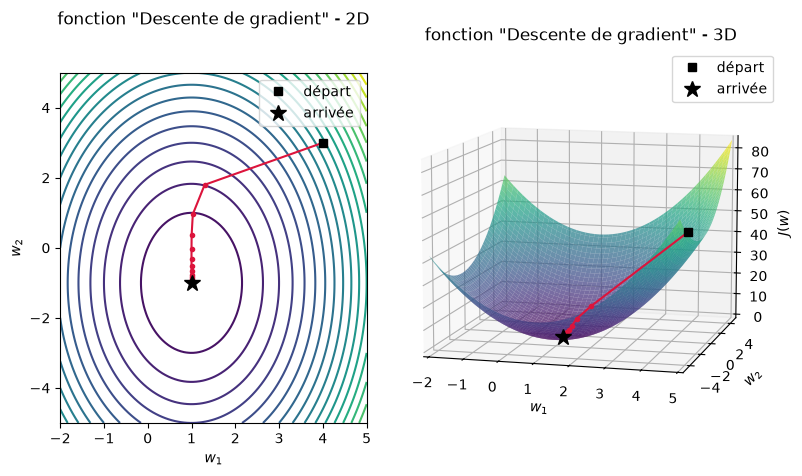

Momentum              :  146 itérations -> w* = [ 1. -1.]


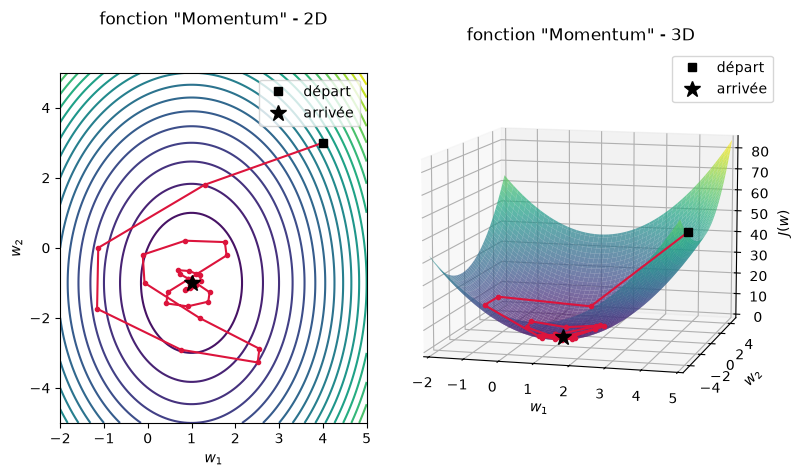

Nesterov              :   52 itérations -> w* = [ 1. -1.]


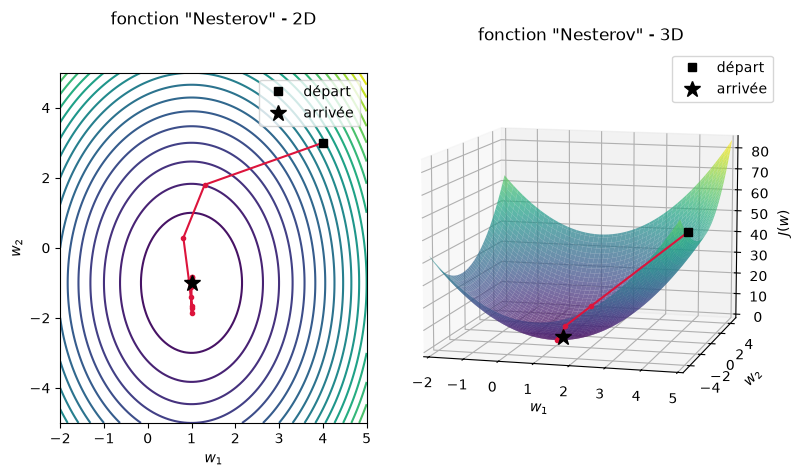

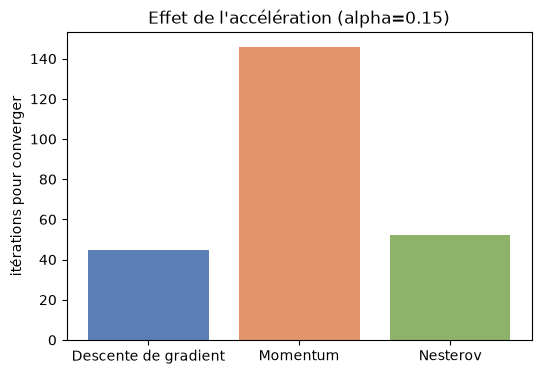

In [9]:
# test et affichage
def J_quad(w): return 3 * (w[0]-1) ** 2 + (w[1]+1) ** 2

results = {}
alpha = 0.15
beta = 0.8
epochs=500
eps=1e-6
w_init=[4.0, 3.0]

for name, fn in [
    ("Descente de gradient", lambda: gradient_descent(J_quad, w_init=w_init, alpha=alpha, epochs=epochs, eps=eps)),  # A COMPLETER : lambda: gradient_descent(J_quad, [4.0, 3.0], 0.15, 500, eps=1e-6)
    ("Momentum", lambda: momentum_gd(J_quad, w_init=w_init, alpha=alpha, beta=beta, epochs=epochs, eps=eps, nesterov=False)), # A COMPLETER : lambda: momentum_gd(J_quad, [4.0, 3.0], 0.15, 0.8, 500, eps=1e-6)
    ("Nesterov", lambda: momentum_gd(J_quad, w_init=w_init, alpha=alpha, beta=beta, epochs=epochs, eps=eps , nesterov=True)), # A COMPLETER : lambda: momentum_gd(..., nesterov=True)
]:
    w_star, hist = fn()
    results[name] = len(hist) - 1
    print(f"{name:22s}: {len(hist)-1:4d} itérations -> w* = {np.round(w_star, 4)}")
    show_history_3d(history=hist, cost_fun=J_quad, xlim=(-2,5,100), ylim=(-5,5,100), title=f'fonction "{name}"')

plt.figure()
plt.bar(list(results.keys()), list(results.values()), color=["#5B7FB5", "#E3946A", "#8CB369"])
plt.ylabel("itérations pour converger")
plt.title("Effet de l'accélération (alpha=0.15)")
plt.show()


**Vos observations :**  
*Le résultat vous surprend-il ? Le momentum est-il plus rapide que la descente de gradient simple **ici** ?  
Indice : le conditionnement de `J_quad` est modéré ($\kappa=3$)*

>Le `momentum` - conçu pour etre plus rapide - est pourtant moins rapide que la descente de gradient. Nous le voyons plus nettement sur la trajectoire (graphique). Le conditionnement est modéré, graphiquement cela se voit pusiqu'il n'y a pas de vallée, les lignes de niveau sont presque en cercle.
>
>Dans le `Momentum`, le terme $\beta \mathbf{v}_k$ ajoute une "accélération" dans le sens de la trajectoire, ce qui explique l'effet de tourner en rond. Dans la suite, nous voyons qu'avec une valeur plus grand ede $\beta$, l'effet est plus marquant.
>
>La methode `Nesterov`, s'en sort mieux car le gradient prend en compte le terme (($\mathbf{w}_k + \beta \mathbf{v}_k$) et permet de limiter l'inertie (la trajectoire se corrige mieux).

*Essayez de refaire ce comparatif avec un `J_quad` bien plus mal conditionné (remplacez le `3` par `30` ou `300`) pour voir ce que ça change.*

>Avec un $\kappa$ bien plus élevé, la surface de la fonction de cout formera une vallée plus prononcée. le `Momentum` (a fortiori le `Nesterov`) sont plus rapides.  
>
>**Note**, selon $\kappa$ il nous faut adapter $\alpha$ en conséquence.

Descente de gradient  :  530 itérations -> w* = [ 1. -1.]


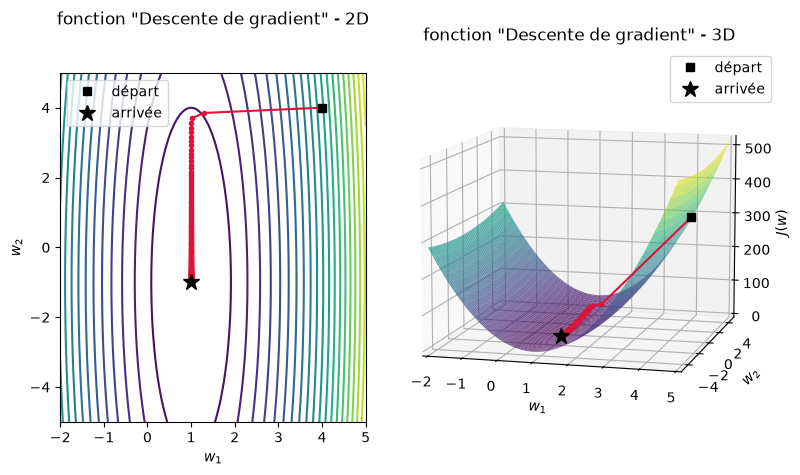

Momentum              :  326 itérations -> w* = [ 1. -1.]


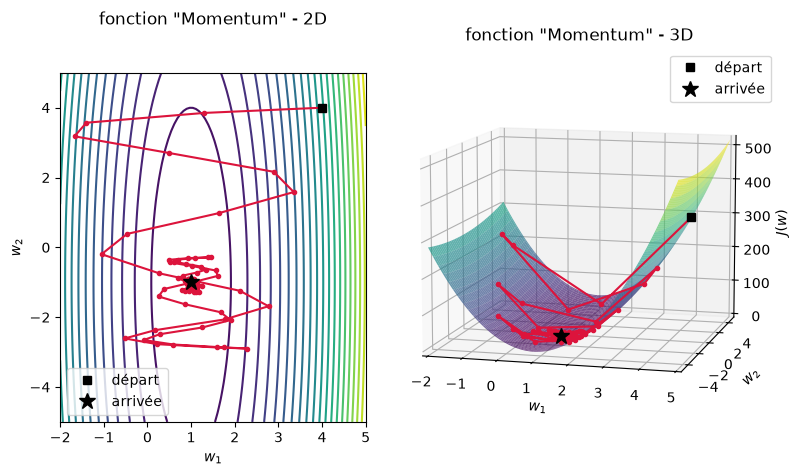

Nesterov              :  200 itérations -> w* = [ 1. -1.]


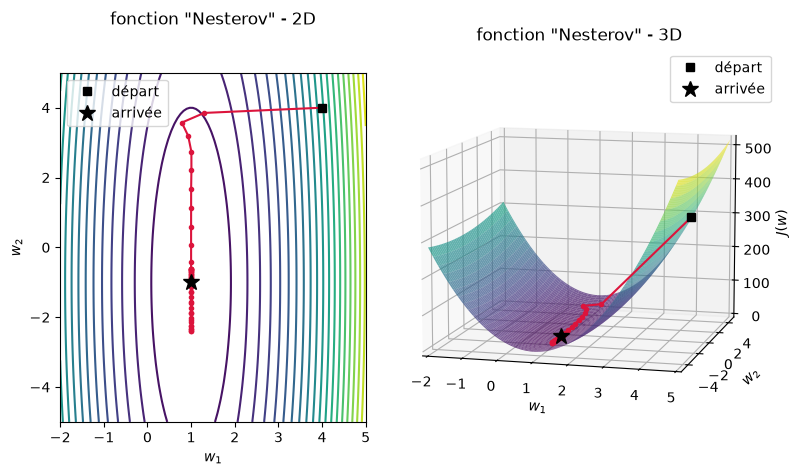

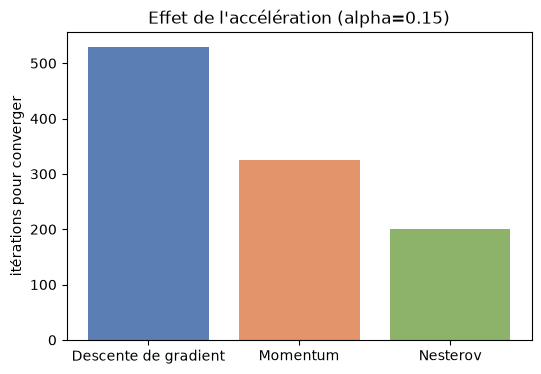

In [10]:
# Test avec un J_quad mal conditionné
def J_quad_bis(w): return 30 * (w[0]-1) ** 2 + (w[1]+1) ** 2

results = {}
alpha = 0.015
beta = 0.9 # un peu plus fort pour marquer l'effet
epochs=1000
eps=1e-6
w_init=[4.0, 4.0]

for name, fn in [
    ("Descente de gradient", lambda: gradient_descent(J_quad_bis, w_init=w_init, alpha=alpha, epochs=epochs, eps=eps)),  # A COMPLETER : lambda: gradient_descent(J_quad, [4.0, 3.0], 0.15, 500, eps=1e-6)
    ("Momentum", lambda: momentum_gd(J_quad_bis, w_init=w_init, alpha=alpha, beta=beta, epochs=epochs, eps=eps, nesterov=False)), # A COMPLETER : lambda: momentum_gd(J_quad, [4.0, 3.0], 0.15, 0.8, 500, eps=1e-6)
    ("Nesterov", lambda: momentum_gd(J_quad_bis, w_init=w_init, alpha=alpha, beta=beta, epochs=epochs, eps=eps , nesterov=True)), # A COMPLETER : lambda: momentum_gd(..., nesterov=True)
]:
    w_star, hist = fn()
    results[name] = len(hist) - 1
    print(f"{name:22s}: {len(hist)-1:4d} itérations -> w* = {np.round(w_star, 4)}")
    show_history_3d(history=hist, cost_fun=J_quad_bis, xlim=(-2,5,100), ylim=(-5,5,100), title=f'fonction "{name}"')

plt.figure()
plt.bar(list(results.keys()), list(results.values()), color=["#5B7FB5", "#E3946A", "#8CB369"])
plt.ylabel("itérations pour converger")
plt.title("Effet de l'accélération (alpha=0.15)")
plt.show()

## Exercice 3 — Optimisation continue sous contraintes

Considérons
$$ \min_{x_1,x_2} \; (x_1 - 3/2)^2 + (x_2 - 1/2)^4 \quad \text{s.c.} \quad |x_1| + |x_2| \le 1 .$$

**3.1** Résolvez-le de **trois façons indépendantes**, une cellule à la fois, et vérifiez qu'elles s'accordent.

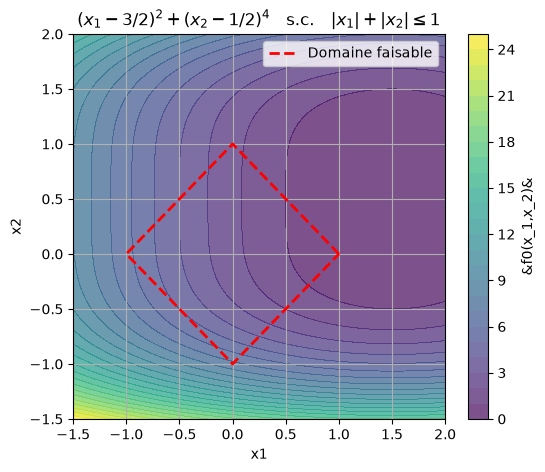

In [11]:
# petitz représentaiton pour voir deja :
import matplotlib.pyplot as plt

def f0(x1, x2):
    return (x1 - 1.5) ** 2 + (x2 - 0.5) ** 4

# Grille pour les contours
x1 = np.linspace(-1.5, 2, 400)
x2 = np.linspace(-1.5, 2, 400)
X1, X2 = np.meshgrid(x1, x2)
Z = f0(X1,X2)
 

# Tracé
plt.figure(figsize=(6, 5))
plt.contourf(X1, X2, Z, levels=30, cmap='viridis', alpha=0.7)
plt.colorbar(label="&f0(x_1,x_2)&")

# Domaine contraint (|x1| + |x2| <= 1 -> losange)
poly_x = [1, 0, -1, 0, 1]
poly_y = [0, 1, 0, -1, 0]
plt.plot(poly_x, poly_y, 'r--', lw=2, label="Domaine faisable")

plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.title("$(x_1 - 3/2)^2 + (x_2 - 1/2)^4\\quad \\text{s.c.} \\quad |x_1| + |x_2| \\leq 1 $")
plt.grid(True)
plt.show()

**(a) Barrière logarithmique.**  
L'idée : remplacer les 4 contraintes linéaires équivalentes à $|x_1|+|x_2|\le 1$  
(à savoir $g_i(x)\ge 0$ pour $g_1=1-x_1-x_2$, $g_2=1+x_1+x_2$, $g_3=1-x_1+x_2$, $g_4=1+x_1-x_2$)  

par une pénalité $-\xi\sum_i \log g_i(x)$ ajoutée à l'objectif, et résoudre un problème **non contraint** avec `scipy.optimize.minimize` (méthode Nelder-Mead).

In [12]:
import numpy as np
from scipy.optimize import minimize

def f0(x1, x2):
    return (x1 - 1.5) ** 2 + (x2 - 0.5) ** 4

def f0_barrier(x, xi=0.05):
    x1, x2 = x
    # A COMPLETER : g = liste des 4 contraintes [1-x1-x2, 1+x1+x2, 1-x1+x2, 1+x1-x2]
    g = [
        1-x1-x2,
        1+x1+x2,
        1-x1+x2,
        1+x1-x2
    ]

    # si min(g) <= 0 : renvoyer une grande pénalité (ex. 1e6) -- on est hors du domaine faisable
    if min(g) <= 0 :
        return 1e6 # et on sort
    
    # sinon : renvoyer f0(x1, x2) - xi * somme(log(g_i))
    return (f0(x1,x2) -xi*sum(np.log(g)))
    # raise NotImplementedError("Complétez f0_barrier")

sol_barrier = minimize(f0_barrier, x0=[0.0, 0.0], args=(0.01,), method="Nelder-Mead")
print("solution barrière :", sol_barrier.x, "f0 =", f0(*sol_barrier.x))


solution barrière : [0.97646494 0.01045112] f0 = 0.3315249641892746


**(b) SLSQP avec contraintes explicites.** Cette fois, on passe directement les 4 contraintes $g_i(x)\ge 0$ à `scipy.optimize.minimize(..., method="SLSQP", constraints=...)`, sans les transformer en pénalité.

In [13]:
# A COMPLETER : cons = tuple de 4 dicts {"type": "ineq", "fun": lambda x: g_i(x)}
cons = (
    {'type':'ineq', 'fun': (lambda x: 1-x[0]-x[1]) },
    {'type':'ineq', 'fun': (lambda x: 1+x[0]+x[1]) },
    {'type':'ineq', 'fun': (lambda x: 1-x[0]+x[1]) },
    {'type':'ineq', 'fun': (lambda x: 1+x[0]-x[1]) },
)

sol_slsqp = minimize(lambda x: f0(x[0], x[1]), x0=[0.0, 0.0], method="SLSQP", constraints=cons)
print("solution SLSQP    :", sol_slsqp.x, "f0 =", f0(*sol_slsqp.x))


solution SLSQP    : [ 1.00000000e+00 -9.43689571e-16] f0 = 0.31250000000000133


**(c) `cvxpy`.** Le problème est convexe : formulez-le directement en `cvxpy` (variables, contrainte `cp.abs(x1) + cp.abs(x2) <= 1`, objectif, `prob.solve()`).

In [14]:
import cvxpy as cp
# https://www.cvxpy.org/api_reference/cvxpy.html
# avec un exemple contraint : https://www.cvxpy.org/examples/basic/sdp.html

# on remet la fonction au cas ou :
def f0(x1, x2):
    return (x1 - 1.5) ** 2 + (x2 - 0.5) ** 4

# A COMPLETER : 
# Définition des variables de décision : x1, x2 = cp.Variable()
x1 = cp.Variable()
x2 = cp.Variable()

# constraints = [...] ;
cons = [cp.abs(x1) + cp.abs(x2) <= 1]

# obj = cp.Minimize(...) ;
obj = cp.Minimize(f0(x1, x2))

# prob = cp.Problem(obj, constraints) ;
prob = cp.Problem(obj, constraints=cons) # type: ignore
prob.solve()

# raise NotImplementedError("Complétez la formulation cvxpy")
print("solution cvxpy :", x1.value, x2.value, "f0 =", prob.value)



solution cvxpy : 0.9999999934456898 2.218611322625575e-09 f0 = 0.3125000054450046


**✅ Vérification 3.1** — les trois méthodes doivent tomber sur (à peu près) le même point.

In [15]:
_pts = {
    "barrière": np.array(sol_barrier.x),
    "SLSQP": np.array(sol_slsqp.x),
    "cvxpy": np.array([x1.value, x2.value]),
}
for name, p in _pts.items():
    print(f"  {name:10s}: {np.round(p, 4)}")
_ref = _pts["SLSQP"]
for name, p in _pts.items():
    assert np.linalg.norm(p - _ref) < 0.05, f"{name} s'écarte trop de SLSQP : {p} vs {_ref}"
print("OK : les trois méthodes s'accordent (à 0.05 près).")


  barrière  : [0.9765 0.0105]
  SLSQP     : [ 1. -0.]
  cvxpy     : [1. 0.]
OK : les trois méthodes s'accordent (à 0.05 près).


**3.2 — Multiplicateurs de Lagrange à la main.** Écrivez les quatre contraintes sous la forme $g_i(x) \ge 0$ :
$$ g_1 = 1-x_1-x_2,\quad g_2 = 1+x_1+x_2,\quad g_3 = 1-x_1+x_2,\quad g_4 = 1+x_1-x_2 . $$
Identifiez numériquement quelles $g_i$ sont actives (nulles) à l'optimum — vous devriez trouver **deux** contraintes actives simultanément, car l'optimum se situe exactement sur un *sommet* du losange $|x_1|+|x_2|\le 1$ (le même phénomène qu'un sommet optimal du polytope d'un PL !). Sur une feuille, écrivez la condition de stationnarité KKT avec les deux multiplicateurs correspondants,
$$ \nabla f_0(x^\star) = \mu_1 \nabla g_1(x^\star) + \mu_3 \nabla g_3(x^\star), \qquad \mu_1,\mu_3 \ge 0, $$
résolvez le système linéaire 2×2 obtenu **à la main**, puis codez le même calcul ci-dessous pour vérifier votre résultat papier.

### **Solution**

La solution iptimum est en $x^\star=(1,0)$
$$
\begin{aligned}
g_1 = 1 - 1 - 0 &= 0 &\quad &\text{active} \\
g_2 = 1 + 1 + 0 &= 2 &\quad &\text{inactive} \\
g_3 = 1 - 1 + 0 &= 0 &\quad &\text{active} \\
g_4 = 1 + 1 - 0 &= 2 &\quad &\text{inactive} \\
\end{aligned}
$$
  
  
Nous allons résoudre :  
$$\nabla f_0(x^\star) = \mu_1 \nabla g_1(x^\star) + \mu_3 \nabla g_3(x^\star)$$

Nous avons déjà la gradien de $f_0$ :  
$$\nabla f_0(x_1, x_2) = \begin{pmatrix} 2(x_1 - 3/2) \\ 4(x_2 - 1/2)^3 \end{pmatrix}$$
Si on remplace par $x_1=1, x_2=0$ :
$$\nabla f_0(1,0) = \begin{pmatrix} -1 \\ -1/2 \end{pmatrix}$$
  
$$ g_1 = 1-x_1-x_2,\quad g_3 = 1-x_1+x_2$$
$$ \nabla g_1 = \begin{pmatrix} -1 \\ -1 \end{pmatrix} \quad \nabla g_2 = \begin{pmatrix} -1 \\ +1 \end{pmatrix}$$
$$\begin{pmatrix} -1 \\ -1/2 \end{pmatrix} = \begin{pmatrix} -\mu_1 - \mu_3 \\ -\mu_1 + \mu_3 \end{pmatrix}$$

On résoud le système d'équation à deux inconnus et cela donne : 
$$\mu_1 = 3/4, \mu_2=1/4 \quad \quad \mu_1,\mu_2 \ge 0$$



In [16]:
x_star = np.array(sol_slsqp.x)
g = [1 - x_star[0] - x_star[1], 1 + x_star[0] + x_star[1],
     1 - x_star[0] + x_star[1], 1 + x_star[0] - x_star[1]]
print("valeurs des contraintes g1..g4 :", np.round(g, 4), " (0 = active)")

# A COMPLETER :
# grad_f0 = gradient de f0 en x_star : (2*(x1-1.5), 4*(x2-0.5)**3)
# M = matrice 2x2 dont les COLONNES sont grad(g1)=(-1,-1) et grad(g3)=(-1,1)
# mu = solution de M @ mu = grad_f0  (np.linalg.solve)
grad_f0 = np.array([
    2*(x_star[0]-1.5),
    4*(x_star[1]-0.5)**3]
    )
M = np.column_stack([
    [-1,-1],
    [-1,1]]
    )
mu = np.linalg.solve(M,grad_f0)
print("mu1, mu3 =", np.round(mu, 4), " (les deux doivent être >= 0 : complémentarité vérifiée)")


valeurs des contraintes g1..g4 : [ 0.  2. -0.  2.]  (0 = active)
mu1, mu3 = [0.75 0.25]  (les deux doivent être >= 0 : complémentarité vérifiée)


**✅ Vérification 3.2** — la stationnarité KKT doit être satisfaite (résidu quasi nul) et les deux multiplicateurs doivent être positifs.

In [17]:
_grad_g1, _grad_g3 = np.array([-1, -1]), np.array([-1, 1])

_residual = grad_f0 - (mu[0] * _grad_g1 + mu[1] * _grad_g3)
assert np.linalg.norm(_residual) < 1e-4, f"stationnarité KKT non vérifiée, résidu = {_residual}"
assert mu[0] > -1e-6 and mu[1] > -1e-6, f"les deux multiplicateurs doivent être >= 0, obtenu {mu}"
print(f"OK : résidu KKT = {np.linalg.norm(_residual):.2e}, mu = {np.round(mu, 4)} (>= 0)")


OK : résidu KKT = 0.00e+00, mu = [0.75 0.25] (>= 0)


## Exercice 4 — Programmation linéaire : mix de production

Avant l'extension de sa gamme avec le modèle **Sport** (voir le Projet, Partie 1 ci-dessous, pour la gamme réelle à trois produits), ExedBike ne fabriquait que deux modèles de vélos électriques : **Urban** (marge 120€/unité) et **Cargo** (marge 200€/unité) — c'est cette version simplifiée, déjà résolue à la main en TD1 (Partie ExedBike — Résolution), que nous reprenons ici pour la vérifier avec un solveur.
Chaque semaine, l'usine dispose de **480 heures de main-d'œuvre**, **900 kg d'aluminium pour batteries**, et **240 heures-machine**.

| Ressource            | Urban | Cargo | Disponible |
|---------------------|:----:|:----:|:---:|
| Main-d'œuvre (h/unité)      | 4    | 6    | 480 |
| Aluminium (kg/unité)  | 6    | 15    | 900 |
| Temps machine (h/unité)| 2    | 2    | 240 |

**4.1a** Formulez et résolvez le PL avec `scipy.optimize.linprog` (rappel : `linprog` **minimise** — pour maximiser la marge, minimisez son opposé).

Object : minimiser $ -z=-120u-200c$
  
Considérons la forme matricielle du système de contraintes
$$\text{soit}\quad AX\le b,\quad X\ge0$$

$$
A=\begin{pmatrix}
4 & 6  \\
6 & 15  \\
2 & 2 
\end{pmatrix},
\ 
X=\begin{pmatrix}
\begin{matrix}
u \\ c 
\end{matrix}
\end{pmatrix},
\ 
b=\begin{pmatrix}
480 \\ 900 \\ 240
\end{pmatrix}
$$



In [18]:
from scipy.optimize import linprog

# A COMPLETER :
# c      = coefficients de l'objectif A MINIMISER (donc l'opposé des marges 120, 200)
# A_ub   = matrice des 3 contraintes <=  (main-d'oeuvre, aluminium, temps machine)
# b_ub   = second membre des 3 contraintes [480, 900, 240]

# array de taille (n,) où n = nombre de variables
c = np.array([-120,-200])

# array de taille (m, n) où m = nombre de contraintes
A_ub = np.array([[4,6],[6,15],[2,2]])

# array de taille (m,)
b_ub = [480,900,240]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=(0, None), method="highs")
print("scipy.optimize.linprog :")
print("  Urban =", round(res.x[0], 2), " Cargo =", round(res.x[1], 2),
      " marge hebdomadaire = ", round(-res.fun, 2), "€")


scipy.optimize.linprog :
  Urban = 75.0  Cargo = 30.0  marge hebdomadaire =  15000.0 €


**4.1b** Formulez le **même** PL avec `PuLP` (langage plus proche de l'écriture mathématique : variables, objectif à *maximiser* directement, contraintes une par une).

In [20]:
# Attention ! il faut la version 3.3.2, pas la dernière (4.0.0)
# uv pip uninstall pulp
# uv pip install pulp==3.3.2
import pulp

prob = pulp.LpProblem("ExedBike_mix", pulp.LpMaximize)
# A COMPLETER :
# u, cg  = deux LpVariable (Urban, Cargo), bornées >= 0 (lowBound=0)
# prob  += l'objectif 120*u + 200*cg
# prob  += les 3 contraintes de ressources (<= 480, <= 900, <= 240), avec un nom pour chacune
u = pulp.LpVariable('Urban',lowBound=0)
cg = pulp.LpVariable("Cargo", lowBound=0)
prob += (120*u + 200*cg)
prob += (4*u + 6*cg) <= 480
prob += (6*u + 15*cg) <= 900
prob += (2*u + 2*cg) <= 240

prob.solve(pulp.PULP_CBC_CMD(msg=False))
print("Statut PuLP :", pulp.LpStatus[prob.status])
print("Urban =", u.value(), " Cargo =", cg.value(), " marge = ", pulp.value(prob.objective), "€")

for name, con in prob.constraints.items():
    print(f"  {name:14s} marge de manoeuvre = {con.slack:.2f}  (saturée : {abs(con.slack) < 1e-6})")


Statut PuLP : Optimal
Urban = 75.0  Cargo = 30.0  marge =  15000.0 €
  _C1            marge de manoeuvre = -0.00  (saturée : True)
  _C2            marge de manoeuvre = -0.00  (saturée : True)
  _C3            marge de manoeuvre = 30.00  (saturée : False)


**✅ Vérification 4.1** — `scipy` et `PuLP` doivent donner exactement la même marge optimale (et la même que votre tableau de simplexe à la main en TD1 : 15 000 €).

In [21]:
_obj_scipy = -res.fun
_obj_pulp = pulp.value(prob.objective)
assert abs(_obj_scipy - _obj_pulp) < 1e-2, f"scipy ({_obj_scipy}) et PuLP ({_obj_pulp}) ne s'accordent pas"
assert abs(_obj_scipy - 15000) < 1.0, f"attendu 15 000 € (cf. TD1), obtenu {_obj_scipy}"
print(f"OK : scipy = {_obj_scipy:.2f} € ; PuLP = {_obj_pulp:.2f} € ; TD1 (à la main) = 15000 €")


OK : scipy = 15000.00 € ; PuLP = 15000.00 € ; TD1 (à la main) = 15000 €


**4.2** Quelles contraintes sont saturées à l'optimum ? Correspondent-elles au sommet identifié à la main en TD ? Sur quelle ressource faudrait-il investir en priorité ? Affichez les prix duaux (`prob.constraints[name].pi` en PuLP, `res.ineqlin.marginals` en `linprog`) et interprétez-les.

In [22]:
# A COMPLETER : affichez les prix duaux de chaque contrainte, pour PuLP (con.pi) et pour scipy (res.ineqlin.marginals)
print("Prix duaux (PuLP) :")
for name, con in prob.constraints.items(): 
    print(f"{name} = {round(con.pi,2)}") # type: ignore

print("\nValeurs duales (scipy) :")
for i, item in enumerate(res.ineqlin.marginals) :
    print(f"C{i+1:01} : {-round(item,2)}") # signe - car scipy minimise


Prix duaux (PuLP) :
_C1 = 25.0
_C2 = 3.33
_C3 = -0.0

Valeurs duales (scipy) :
C1 : 25.0
C2 : 3.33
C3 : 0.0


>Les contraintes saturées (con.slack = 0) sont les C1 et C2. Cela correspond bien à ce qui a été trouvé en TD.  
>
>Le prix dual d'une contrainte représente : "Combien la marge optimale augmenterait si on disposait d'une unité supplémentaire de cette ressource ?" 
>Ainsi il faut investir en priorité sur la contrainte C1 (25€/unité en +) donc la main d'oeuvre, puis ensuite sur l'aluminium (C2)

---
## Projet individuel ExedBike — Partie 1 (à rendre avant la Séance 2)

Vous allez travailler sur ce **projet fil rouge** tout au long des trois séances. Lisez le brief complet du projet (document séparé) pour le contexte, les jalons et les critères d'évaluation. Voici la **Partie 1** — contrairement aux exercices précédents, **c'est votre travail individuel noté** : il n'y a pas de cellule de vérification qui vous donne la réponse.

### 1. Ajuster un modèle de coût de production (optimisation continue)

Les données ci-dessous forment un jeu de données synthétique du coût unitaire de production en fonction du volume cumulé produit pour le modèle Urban (un effet classique de **courbe d'apprentissage** : le coût baisse avec l'expérience accumulée). Le modèle est une loi de puissance,
$$ c(q) = k\, q^{-\theta}, \qquad \theta \in (0,1). $$
En passant au logarithme, ceci devient une **régression linéaire** : $\log c(q) = \log k - \theta \log q$.

In [23]:
# on ajoute les import pour recommencer d'ici
import numpy as np
import matplotlib.pyplot as plt
from autograd import grad
import autograd.numpy as anp

# et on remet la fonction gradient_descent
def gradient_descent(cost_fun, w_init, alpha, epochs, eps=1e-12):
    '''Minimise cost_fun par descente de gradient.

    ENTREES
    cost_fun : callable, fonction de coût J(w)
    w_init   : array-like, point initial
    alpha    : float, pas (learning rate)
    epochs   : int, nombre maximal d'itérations
    eps      : float, arrêt si la norme du gradient passe sous eps

    SORTIES
    w       : point final (np.array)
    history : liste des itérés successifs (y compris w_init)
    '''
    w = np.array(w_init, dtype=float)
    history = [w.copy()]
    # g(w) renvoie le gradient de cost_fun en w (autograd)
    g = grad(cost_fun)   # type: ignore 

    for k in range(epochs):
        # A COMPLETER (3-4 lignes) :
        # 1) calculez gk = g(w) (convertissez en np.array)
        g_k =  np.array(g(w))

        # 2) si la norme de gk est < eps : "break"
        norm = np.linalg.norm(g_k)
        if norm < eps : break

        # 3) sinon : mettez à jour w = w - alpha * gk
        w = w - alpha*g_k

        # 4) ajoutez une copie de w à "history"
        history.append(w.copy())
        # raise NotImplementedError("Complétez gradient_descent")
    
    return w, history

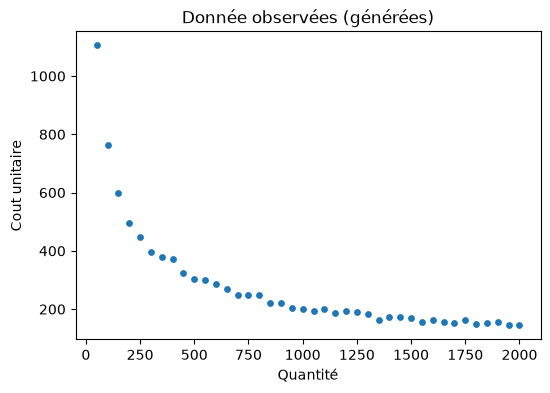

In [56]:
# Jeu de données synthétique (ne changez pas la graine : les résultats doivent être reproductibles)
rng = np.random.default_rng(7)
q = np.linspace(50, 2000, 40)
k_true, theta_true = 9500.0, 0.55
# la fonction cout + un générateur de bruit gaussien (mu=0, sigma=0.04)
c_obs = k_true * q ** (-theta_true) * np.exp(rng.normal(0, 0.04, size=q.shape))

plt.figure()
plt.scatter(q, c_obs, s=15)
plt.xlabel("Quantité")
plt.ylabel("Cout unitaire")
plt.title("Donnée observées (générées)")
plt.show()


Ajustez $(\log k, \theta)$ en minimisant l'erreur quadratique moyenne **avec votre propre implémentation de la descente de gradient** (celle de l'Exercice 1, réutilisable telle quelle) sur les données log-log **standardisées**, puis reportez $(k,\theta)$ dans les unités d'origine. Tracez les données et l'ajustement, ainsi que la courbe de convergence, et expliquez (dans votre synthèse d'une page) pourquoi standardiser $\log q$ compte ici (faites le lien avec le mauvais conditionnement observé à l'Exercice 1.2).

Étapes suggérées :
1. `x = log(q)`, `y = log(c_obs)` ;
2. standardisez `x` : `x_z = (x - x.mean()) / x.std()` ;
3. définissez `J_fit(params)` = EQM entre `p0 - p1*x_z` et `y` (avec `params=[p0,p1]`, en utilisant `anp` pour que `autograd` puisse dériver) ;
4. `gradient_descent(J_fit, w_init=[0.0, 0.0], alpha=..., epochs=...)` ;
5. dé-standardisez : `theta_hat = p1/x_std`, `k_hat = exp(p0 + p1*x_mean/x_std)` ;
6. tracez le nuage de points + la courbe $k\_hat \cdot q^{-\theta\_hat}$, et la courbe de convergence de la perte.

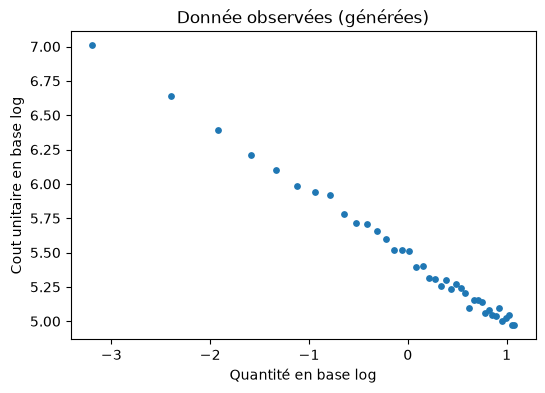

In [58]:
# A COMPLETER (suivez les 6 étapes ci-dessus)

# log log
x = np.log(q)
y = np.log(c_obs)

# standardisation (z)
x_z = (x - x.mean()) / x.std()

# on peut voir deja la tete que ca a et visualiser la linéarité + valeur zscore
plt.figure()
plt.scatter(x_z, y, s=15)
plt.xlabel("Quantité en base log")
plt.ylabel("Cout unitaire en base log")
plt.title("Donnée observées (générées)")
plt.show()

In [59]:
# J_fit
# on défini la fonction de cout et qui est une MSE

def J_fit(params) :
    p0 = params[0]
    p1 = params[1]
    
    # vecteur des prédictions (signe '-' considérant la direction de la droite)
    y_pred = p0 - p1*x_z

    # somme des ecarts au carré
    mse = anp.mean((y - y_pred)**2)
    
    return mse

In [60]:
# gradient_descent
w_init = [0.0, 0.0]

# on prend alpha=0.15
w_opt, hist = gradient_descent(J_fit, w_init=w_init, alpha=0.15, epochs=1000, eps=1e-12)

print(f"convergé en {len(hist)-1} itérations")
print(f"Paramètre p0, p1 : {w_opt}")


convergé en 85 itérations
Paramètre p0, p1 : [5.47471822 0.47883192]


In [61]:
# dé-standardisation ...
x_std = x.std()
x_mean = x.mean()
p0,p1 = w_opt
# on a log(c) = log(k) - theta.log(q)
# y_pred = p0 - p1(x_z)
# y_pred = p0 - p1((x - x_mean)/x_std)
# y_pred = p0 + p1.x_mean/x_std - p1/x.std * x
# avec x = log(q) on reconnait y_pred = log(k_hat) - theta_hat(log(q))
# log(k_hat) = p0 + p1.x_mean/x_std 
# donc :
k_hat = np.exp(p0 + (p1 * x_mean / x_std))
theta_hat = p1 / x_std

print(f"convergé en {len(hist)-1} itérations")
print(f"ajustement : k = {k_hat:.1f}, theta = {theta_hat:.3f}")

# ... graphiques (nuage + ajustement, courbe de convergence) ...


convergé en 85 itérations
ajustement : k = 9682.8, theta = 0.555


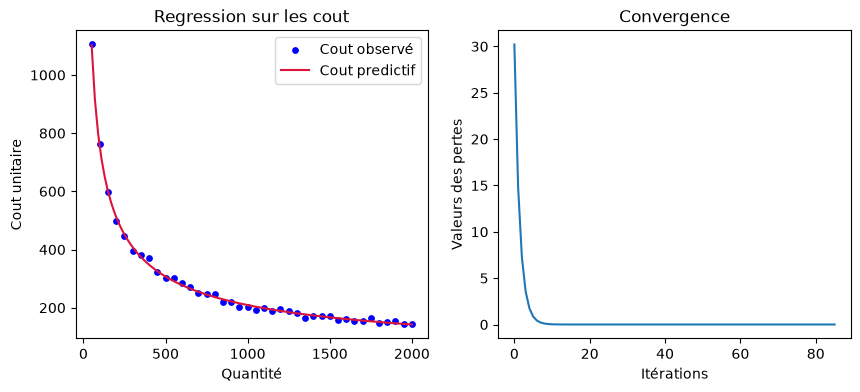

In [ ]:
# Nuage des points initiaux
q_line = np.linspace(q.min(), q.max(), 100)
c_pred = k_hat * q_line ** (-theta_hat)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
# nuage de point pour 
plt.scatter(q, c_obs, s=15, label="Cout observé", color="blue")
# cout prédictif
plt.plot(q_line, c_pred, color="crimson", label=f"Cout predictif")
plt.xlabel("Quantité")
plt.ylabel("Cout unitaire")
plt.title("ajustement sur les cout")
plt.legend()

# convergence : historique des points de w
perte = [J_fit(w) for w in hist]
plt.subplot(1, 2, 2)
plt.plot(perte)
plt.xlabel("Itérations")
plt.ylabel("Valeurs des pertes")
plt.title("Convergence")

# plt.tight_layout()
plt.show()

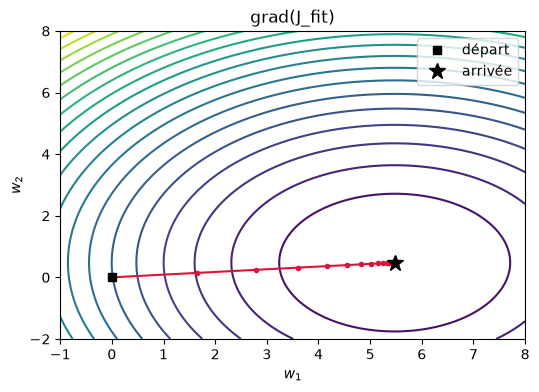

In [69]:
# on reprend la fonction du haut pour voir les itérations de l descente de gradient
show_history(history=hist, cost_fun=J_fit, xlim=(-1,8,100), ylim=(-2,8,100), title='grad(J_fit)')

### 2. PL du mix de production pour la gamme réelle

ExedBike vend en réalité **trois** modèles : Urban, Cargo et Sport, avec les données ci-dessous. Formulez et résolvez le PL du mix de production hebdomadaire (maximiser la marge sous les contraintes de ressources) avec `PuLP` **ou** `scipy.optimize.linprog` — vous savez déjà faire les deux depuis l'Exercice 4, c'est la même démarche avec un troisième produit. Reportez le mix optimal, la marge, les contraintes saturées et les prix duaux, et donnez une phrase d'interprétation métier pour chaque prix dual.

| Ressource | Urban | Cargo | Sport | Disponible |
|---|:--:|:--:|:--:|:--:|
| Main-d'œuvre (h/unité) | 4 | 6 | 5 | 520 |
| Aluminium (kg/unité) | 6 | 15 | 9 | 1100 |
| Temps machine (h/unité) | 2 | 2 | 3 | 260 |
| Marge (€/unité) | 120 | 200 | 175 | — |

#### Formulation du PL

Nous utiliserons `pulp`, inutile ainsi de transformer la fonction en fonction à minimiser.

Object : maximiser $ z = 120u + 200c + 175s$

$$
s.c.\quad \left\{\begin{aligned}
\quad \text{main}\ \text{d'oeuvre}&\quad &\ 4U+6C+5S+x_{1}&=520 \\
\quad \text{aluminium}&\quad &\ 6U+15C+9S+x_{2}&=1100 \\
\quad \text{temp machine}&\quad &\ 2U+2C+3S+x_{3}&=260 \\
\quad \text{domaine}&\quad &\ U,C,S,x_{1},x_{2},x_{3}&\geq 0\ \text{et}\ U,C,S\in \mathbb{R}\end{aligned}\right.
$$


Considérons la forme matricielle du système de contraintes
$$\text{soit}\quad AX\le b,\quad X\ge0$$

$$
A=\begin{pmatrix}
4 & 6 & 5 \\
6 & 15 & 9 \\
2 & 2 & 3
\end{pmatrix},
\ 
X=\begin{pmatrix}
\begin{matrix}
u \\ c \\ s
\end{matrix}
\end{pmatrix},
\ 
b=\begin{pmatrix}
520 \\ 1100 \\ 260
\end{pmatrix}
$$


In [ ]:
# A COMPLETER — Partie 1, Question 2 (à rendre) :
# 1) Définissez vos 3 variables de décision (Urban, Cargo, Sport)
# 2) Écrivez l'objectif : maximiser la marge totale
# 3) Écrivez les 3 contraintes de ressources (table ci-dessus)
# 4) Résolvez avec scipy.optimize.linprog OU PuLP (au choix -- un seul suffit ici)
# 5) Affichez : mix optimal, marge totale, contraintes saturées, prix duaux

In [79]:
# Attention ! il faut la version 3.3.2, pas la dernière (4.0.0)
# uv pip uninstall pulp
# uv pip install pulp==3.3.2
import pulp

# 1) définisson les variables de décisions
u = pulp.LpVariable('Urban',lowBound=0)
c = pulp.LpVariable("Cargo", lowBound=0)
s = pulp.LpVariable("Sport", lowBound=0)

# 2) Objectif 
prob = pulp.LpProblem("ExedBike_mix", pulp.LpMaximize)
prob += (120*u + 200*c + 175*s)

# 3) Contraintes
prob += (4*u + 6*c + 5*c) <= 520
prob += (6*u + 15*c + 9*s) <= 1100
prob += (2*u + 2*c + 3 * s) <= 260

# 4) Résolution
prob.solve(pulp.PULP_CBC_CMD(msg=False))
print("Statut PuLP :", pulp.LpStatus[prob.status])

# 5) mix optimal + marge total
print("---------------------------------------------------")
print("Urban =", u.value(), " Cargo =", c.value(), " Sport =", s.value(), " marge = ", pulp.value(prob.objective), "€")

# contraintes saturées ou pas
for name, con in prob.constraints.items():
    print(f"{name} : marge de manoeuvre = {con.slack:.2f}  (saturée : {abs(con.slack) < 1e-6})")

# et prix duaux
print("---------------------------------------------------")
print("Prix duaux (PuLP) :")
for name, con in prob.constraints.items(): 
    print(f"{name} = {round(con.pi,2)}") # type: ignore

Statut PuLP : Optimal
---------------------------------------------------
Urban = 32.222222  Cargo = 35.555556  Sport = 41.481481  marge =  18237.037015 €
_C1 : marge de manoeuvre = -0.00  (saturée : True)
_C2 : marge de manoeuvre = -0.00  (saturée : True)
_C3 : marge de manoeuvre = -0.00  (saturée : True)
---------------------------------------------------
Prix duaux (PuLP) :
_C1 = 0.83
_C2 = 8.24
_C3 = 33.61


### Livrables pour la Partie 1 (à rendre sous forme d'un seul notebook + une synthèse PDF d'une page)
- Ce notebook complété : Exercices 1 à 4 (toutes les cellules `# A COMPLETER`, vérifications au vert) et les deux tâches du projet ci-dessus.
- Une courte synthèse (≤1 page) : paramètres du modèle de coût ajusté, mix de production optimal, et un paragraphe interprétant les prix duaux pour le directeur d'usine (langage non technique).

Ce travail sera prolongé en Séances 2 et 3 (décisions sur les lignes de production, ordonnancement, réseau de distribution).